In [3]:
import Pyro4
import numpy as np
import matplotlib.pyplot as plt
import threading
import time
import os
import ntpath
import sys
from pathlib import Path

from lmfit.models import LinearModel

HYDRAHARP_BASE_RES_S = 4e-12

def my_find_nearest(ar, target):
    return int((np.abs(ar - target)).argmin())
import matplotlib

In [17]:
# Client/server connection
Pyro4.config.SERIALIZER = "pickle"
Pyro4.config.SERIALIZERS_ACCEPTED = {"pickle"}
Pyro4.config.SERVERTYPE = "thread"
Pyro4.config.THREADPOOL_SIZE = 40
Pyro4.config.THREADPOOL_SIZE_MIN = 4

SERVER_URI = "PYRO:Analysis_g13@g13-sspd.dhcp-int.phys.ethz.ch:9099"
# SERVER_URI = "PYRO:Analysis_g13@127.0.0.1:9099"
URI = SERVER_URI  # Backward-compatible alias for older cells.

try:
    stop_logs.set()
except NameError:
    pass


def analysis_setup(uri=SERVER_URI):
    global analysis_cmd, stop_logs
    analysis_cmd = Pyro4.Proxy(uri)
    stop_logs = threading.Event()

    def log_poller():
        analysis_log = Pyro4.Proxy(uri)
        idx = 0
        progress_active = False
        while not stop_logs.is_set():
            try:
                idx, lines = analysis_log.get_logs(idx, timeout=2.0)
                for line in lines:
                    if line.startswith("\r"):
                        sys.stdout.write('\r\033[K')
                        sys.stdout.write(line[1:])
                        sys.stdout.flush()
                        progress_active = True
                    else:
                        if progress_active:
                            sys.stdout.write('\n')
                            sys.stdout.flush()
                            progress_active = False
                        print(line, flush=True)
            except Exception as exc:
                if progress_active:
                    sys.stdout.write('\n')
                    sys.stdout.flush()
                    progress_active = False
                print(f"[log poller] {exc}", flush=True)
                time.sleep(0.5)
            time.sleep(0.2)

    threading.Thread(target=log_poller, daemon=True).start()
    print("------------------ LOG ------------------", flush=True)
    analysis_cmd.ping()
    return analysis_cmd


def re_bin(x, y, n_new_bins_approx):
    n_new_bins_approx = int(n_new_bins_approx)
    if n_new_bins_approx <= 0:
        raise ValueError("n_new_bins_approx must be positive")
    len_new_bins = max(1, len(x) // n_new_bins_approx)
    n_new_bins = len(x) // len_new_bins
    stop = n_new_bins * len_new_bins
    x_rebin = np.mean(np.asarray(x[:stop]).reshape(n_new_bins, len_new_bins), axis=1)
    y_rebin = np.sum(np.asarray(y[:stop]).reshape(n_new_bins, len_new_bins), axis=1)
    return x_rebin, y_rebin


def rebin_plot(tau, hist, n_new_bins=None, ref_range_s=None, x_limit_us=None, y_limit=None,
               title=None, savepath=None, y_offset=0):
    plt.figure(figsize=(10, 2.8))
    if ref_range_s is not None:
        tau_rebin, h_rebin_detrend, stdv_h, h_0 = g2izer(tau, hist, n_new_bins, ref_range_s)
        bg_range = [my_find_nearest(tau_rebin, ref_range_s[0]), my_find_nearest(tau_rebin, ref_range_s[1])]
        plt.plot(tau_rebin * 1e6, h_rebin_detrend / h_0 + y_offset, "-o", markersize=4, label="Normalized detrended coincidences")
        plt.plot(tau_rebin[bg_range[0]:bg_range[1]] * 1e6,
                 h_rebin_detrend[bg_range[0]:bg_range[1]] / h_0 + y_offset,
                 "-o", markersize=4, label="Reference range", color="darkred", alpha=0.5)
        for level, label in [(2 * stdv_h / h_0, r"$\pm 2\sigma$"), (-2 * stdv_h / h_0, None), (0, "Mean")]:
            plt.plot([tau_rebin[0] * 1e6, tau_rebin[-1] * 1e6], [level + y_offset, level + y_offset],
                     color="grey" if level else "lightgrey", label=label)
        plt.ylabel(r"$g^{(2)}(\tau) - 1$")
    else:
        tau_rebin, h_rebin = g2izer(tau, hist, n_new_bins, ref_range_s)
        plt.plot(tau_rebin * 1e6, h_rebin + y_offset, "-o", markersize=4, label="Coincidences per bin")
        plt.ylabel("Coincidences per bin")

    if x_limit_us is not None:
        plt.xlim(-x_limit_us / 50, x_limit_us)
    if y_limit is not None:
        plt.ylim(*y_limit)
    if title is not None:
        bin_size_ns = int((tau_rebin[1] - tau_rebin[0]) * 1e9) if len(tau_rebin) > 1 else 0
        plt.title(f"{title}\nTime delay bin size = {bin_size_ns} ns")
    plt.legend()
    plt.xlabel(r"Time delay $\tau$ (us)")
    plt.tight_layout()
    if savepath is not None:
        plt.savefig(os.path.join(savepath, "classical_analysis.svg"))



In [ ]:


analysis_setup()




------------------ LOG ------------------
HydraHarp analysis server reached.
[ANALYSIS - UTC 2026-05-08 16:58:05] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_0.100V
[ANALYSIS - UTC 2026-05-08 16:58:05] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.005V


<Pyro4.core.Proxy at 0x22680603c10; connected IPv4; for PYRO:Analysis_g13@g13-sspd.dhcp-int.phys.ethz.ch:9099>

[ANALYSIS - UTC 2026-05-08 16:58:06] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.006V
[ANALYSIS - UTC 2026-05-08 16:58:07] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.007V
[ANALYSIS - UTC 2026-05-08 16:58:08] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.008V
[ANALYSIS - UTC 2026-05-08 16:58:38] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_0.100V
[ANALYSIS - UTC 2026-05-08 16:58:38] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.005V
[ANALYSIS - UTC 2026-05-08 16:58:39] Reading file with name test_chunk0 in mode X01 from folder 

HydraHarp analysis server reached.
[ANALYSIS - UTC 2026-05-08 17:05:20] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_0.100V
[ANALYSIS - UTC 2026-05-08 17:05:20] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.005V
[ANALYSIS - UTC 2026-05-08 17:05:21] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.006V
[ANALYSIS - UTC 2026-05-08 17:05:21] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.007V
[ANALYSIS - UTC 2026-05-08 17:05:22] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.008V
[ANALYSIS - UTC 2026-05-08 17:06:05] Reading file with name t

# All analysis in one:

In [19]:

def load_or_create_classical_bins(filepath, bin_width_ms=20, chunk_minutes=72,
                                  include_channels=None, force_recompute=False,
                                  show_progress=True):
    classical_folder = str(Path(filepath).with_suffix('')) + "_classical_bins"
    if not force_recompute and Path(classical_folder).exists():
        existing = analysis_cmd.read_existing_classical(
            classical_folder,
            tau_bin_ms=bin_width_ms,
            return_autocorr=True,
        )
        if existing[0]:
            return existing

    classical_folder, _ = analysis_cmd.correlate_b_file_classical(
        filepath=str(filepath),
        tau_bin_ms=bin_width_ms,
        chunk_minutes=chunk_minutes,
        include_channels=include_channels,
        show_progress=show_progress,
        compute_autocorr=True,
    )
    return analysis_cmd.read_existing_classical(
        classical_folder,
        tau_bin_ms=bin_width_ms,
        return_autocorr=True,
    )


def plot_classical_counts(classical_data, title=None, max_chunks=None, histogram_bins="auto",
                          y_lims=None, savepath=None,ac_xlim_s=None):
    if len(classical_data) == 9:
        counts_list, dt_s_list, chunk_minutes_list, chunk_index_list, t0_abs_ticks_list, wrap_ticks_list, min_idx, max_idx, saved_autocorr = classical_data
    else:
        counts_list, dt_s_list, chunk_minutes_list, chunk_index_list, t0_abs_ticks_list, wrap_ticks_list, min_idx, max_idx = classical_data
        saved_autocorr = None

    if not counts_list:
        raise ValueError("No classical bins were found for the requested bin width.")

    if max_chunks is not None:
        counts_list = counts_list[:max_chunks]
        dt_s_list = dt_s_list[:max_chunks]
        chunk_index_list = chunk_index_list[:max_chunks]

    times = []
    counts = []
    elapsed = 0.0
    for chunk_counts, dt_s in zip(counts_list, dt_s_list):
        chunk_counts = np.asarray(chunk_counts)
        t = elapsed + np.arange(chunk_counts.size) * dt_s
        times.append(t)
        counts.append(chunk_counts)
        elapsed = t[-1] + dt_s if t.size else elapsed

    time_s = np.concatenate(times)
    count_values = np.concatenate(counts)
    nonzero_mask = count_values > 0
    nonzero_counts = count_values[nonzero_mask]
    bin_width_s = dt_s_list[0]
    bin_width_ms = bin_width_s * 1e3

    if nonzero_counts.size:
        first_nonzero = int(np.argmax(nonzero_mask))
        last_nonzero = int(len(nonzero_mask) - np.argmax(nonzero_mask[::-1]))
        time_plot_min = time_s[first_nonzero:last_nonzero] / 60.0
        count_plot_values = count_values[first_nonzero:last_nonzero]
    else:
        time_plot_min = time_s / 60.0
        count_plot_values = count_values

    if saved_autocorr is not None:
        autocorr_lag_s = np.asarray(saved_autocorr["lag_s"])
        autocorr = np.asarray(saved_autocorr["autocorr"])
    else:
        signal = count_plot_values.astype(float)
        if signal.size > 1 and np.mean(signal) != 0:
            signal = (signal - np.mean(signal)) / np.mean(signal)
            n = signal.size
            nfft = 1 << (2 * n - 2).bit_length()
            spectrum = np.fft.rfft(signal, n=nfft)
            raw_ac = np.fft.irfft(spectrum * np.conjugate(spectrum), n=nfft)[:n]
            unbiased_norm = np.arange(n, 0, -1)
            autocorr = raw_ac / unbiased_norm
            if autocorr[0] != 0:
                autocorr = autocorr / autocorr[0]
            autocorr_lag_s = np.arange(autocorr.size) * bin_width_s
        else:
            autocorr_lag_s = np.array([])
            autocorr = np.array([])

    if ac_xlim_s is not None:
        lag_mask = autocorr_lag_s <= ac_xlim_s
        autocorr_lag_plot = autocorr_lag_s[lag_mask]
        autocorr_plot = autocorr[lag_mask]
    else:
        autocorr_lag_plot = autocorr_lag_s
        autocorr_plot = autocorr

    fig, (ax_trace, ax_hist, ax_ac) = plt.subplots(
        1,
        3,
        figsize=(9, 2.8),
        width_ratios=(4.2, 1.15, 1.9),
    )

    ax_trace.plot(time_plot_min, count_plot_values, linewidth=0.8)
    ax_trace.set_xlabel("Measurement time (min)")
    ax_trace.set_ylabel(f"Counts / bin")
    if y_lims is not None:
        ax_trace.set_ylim(y_lims)
    if title is not None:
        ax_trace.set_title(title)

    if nonzero_counts.size:
        ax_hist.hist(nonzero_counts, bins=histogram_bins, orientation="horizontal", color="0.35")
    ax_hist.set_xlabel("Occurrences")
    ax_hist.tick_params(axis="y", labelleft=False)
    ax_hist.grid(axis="x", alpha=0.25)
    if y_lims is not None:
        ax_hist.set_ylim(y_lims)
    else:
        ax_hist.set_ylim(ax_trace.get_ylim())

    if autocorr_plot.size:
        ax_ac.plot(autocorr_lag_plot*1e3, autocorr_plot, "-o",linewidth=1.0,markersize = 1)
        ax_ac.axhline(0, color="lightgrey", zorder=0)
    ax_ac.set_xlabel("Delay (ms)")
    ax_ac.set_ylabel("Autocorr.")
    ax_ac.grid(alpha=0.25)

    fig.tight_layout()
    if savepath is not None:
        fig.savefig(os.path.join(savepath, "classical_analysis.svg"))
    fig.show()
    return {
        "time_s": time_s,
        "time_plot_min": time_plot_min,
        "counts": count_values,
        "counts_plot": count_plot_values,
        "nonzero_counts": nonzero_counts,
        "autocorr_lag_s": autocorr_lag_s,
        "autocorr": autocorr,
        "saved_autocorr": saved_autocorr,
        "figure": fig,
        "trace_axis": ax_trace,
        "hist_axis": ax_hist,
        "autocorr_axis": ax_ac,
    }


def analyze_all(paths, ratio_g2_bins=100, ref_range_s=(80e-3, 100e-3),
                correlation_mode="X01", x_limit_us=None, y_limit=None,
                title=None, savepath=None, verbose=True,
                plot_classical=True, classical_bin_width_ms=20,
                classical_chunk_minutes=72, force_classical_recompute=False):
    """
    Load an existing HydraHarp correlation histogram, plot normalized g2 - 1,
    and optionally plot classical count bins versus measurement time.
    """
    base, dataset_name, filename = paths
    filepath = Path(base) / filename
    histogram_name = filename[:-2]
    plot_title = title or dataset_name.strip("\\").replace("\\", "_")

    hist, tau, params = analysis_cmd.read_existing(base, mode=correlation_mode, name=histogram_name)
    n_new_bins = max(1, int(len(tau) / ratio_g2_bins))
    tau_rebin, hist_detrended, hist_std, hist_baseline = g2izer(
        tau,
        hist,
        n_new_bins=n_new_bins,
        ref_range_s=ref_range_s,
        verbose=verbose,
    )

    # g2izer returns the detrended numerator. Divide by the baseline to get g2 - 1.
    g2_minus_1 = hist_detrended / hist_baseline
    ref_start = my_find_nearest(tau_rebin, ref_range_s[0])
    ref_stop = my_find_nearest(tau_rebin, ref_range_s[1])

    fig_g2, ax_g2 = plt.subplots(figsize=(10, 3.2))
    ax_g2.plot(tau_rebin * 1e6, g2_minus_1, "-o", markersize=4, label=r"$g^{(2)}(\tau)-1$")
    ax_g2.plot(
        tau_rebin[ref_start:ref_stop] * 1e6,
        g2_minus_1[ref_start:ref_stop],
        "-o",
        markersize=4,
        color="darkred",
        alpha=0.55,
        label="Reference range",
    )
    ax_g2.axhline(0, color="lightgrey", zorder=0)
    ax_g2.axhline(2 * hist_std / hist_baseline, color="grey", zorder=0, label=r"$\pm 2\sigma$")
    ax_g2.axhline(-2 * hist_std / hist_baseline, color="grey", zorder=0)

    if x_limit_us is not None:
        ax_g2.set_xlim(-x_limit_us / 50, x_limit_us)
    if y_limit is not None:
        ax_g2.set_ylim(*y_limit)

    bin_size_ns = (tau_rebin[1] - tau_rebin[0]) * 1e9 if len(tau_rebin) > 1 else np.nan
    ax_g2.set_title(f"{plot_title}\nTime delay bin size = {bin_size_ns:.3g} ns")
    ax_g2.set_xlabel(r"Time delay $\tau$ (us)")
    ax_g2.set_ylabel(r"$g^{(2)}(\tau) - 1$")
    ax_g2.legend()
    fig_g2.tight_layout()

    if savepath is not None:
        fig_g2.savefig(savepath, dpi=300)
    fig_g2.show()
    classical_result = None
    classical_plot = None
    if plot_classical:
        classical_result = load_or_create_classical_bins(
            filepath,
            bin_width_ms=classical_bin_width_ms,
            chunk_minutes=classical_chunk_minutes,
            force_recompute=force_classical_recompute,
            show_progress=True,
        )
        classical_plot = plot_classical_counts(
            classical_result,
            title=f"{plot_title}\nClassical bins, {classical_bin_width_ms:g} ms",
        )

    return {
        "tau": tau,
        "hist": hist,
        "tau_rebin": tau_rebin,
        "hist_detrended": hist_detrended,
        "g2_minus_1": g2_minus_1,
        "hist_std": hist_std,
        "hist_baseline": hist_baseline,
        "params": params,
        "g2_figure": fig_g2,
        "g2_axis": ax_g2,
        "classical_data": classical_result,
        "classical_plot": classical_plot,
    }



def g2izer(tau, hist, n_new_bins=None, ref_range_s=None, verbose=True, outlier_sigma=7):
    tau = np.asarray(tau, dtype=float)
    hist = np.asarray(hist)

    if n_new_bins is not None:
        if verbose:
            print(f"Rebinning from {len(tau):d} to {int(n_new_bins):d}")
        tau_rebin, h_rebin = re_bin(tau, hist, int(n_new_bins))
    else:
        if verbose:
            print("Not rebinning")
        tau_rebin, h_rebin = tau, hist

    if len(tau_rebin) > 1 and verbose:
        print(f"Bin size {((tau_rebin[1] - tau_rebin[0]) * 1e9):.3g} ns")

    std_raw = np.std(h_rebin)
    if std_raw > 0:
        keep = np.abs(h_rebin - np.mean(h_rebin)) < outlier_sigma * std_raw
        tau_rebin = tau_rebin[keep]
        h_rebin = h_rebin[keep]

    if ref_range_s is None:
        return tau_rebin, h_rebin

    if len(ref_range_s) != 2:
        raise ValueError("ref_range_s must contain exactly two values in seconds")

    lo, hi = sorted(float(v) for v in ref_range_s)
    bg_start = my_find_nearest(tau_rebin, lo)
    bg_stop = my_find_nearest(tau_rebin, hi)
    if bg_stop <= bg_start:
        raise ValueError("ref_range_s does not select a non-empty background region")

    hist_bg = h_rebin[bg_start:bg_stop]
    tau_bg = tau_rebin[bg_start:bg_stop]
    h_0 = float(np.mean(hist_bg))
    if h_0 == 0:
        raise ValueError("Background mean is zero; cannot normalize g2")

    bg_fit = LinearModel()
    edge = min(100, max(1, len(h_rebin) // 4))
    slope_guess = (h_rebin[-edge] - h_rebin[edge]) / (tau_rebin[-edge] - tau_rebin[edge]) / h_0
    fit_params = bg_fit.make_params(slope=slope_guess, intercept=1)
    fitresult = bg_fit.fit(hist_bg / h_0, fit_params, x=tau_bg)
    lin_bg = fitresult.eval(x=tau_rebin)
    h_rebin_detrend = h_rebin - lin_bg * h_0
    std_h = np.std(hist_bg - fitresult.eval(x=tau_bg) * h_0)

    if verbose:
        print(f"Reference range {lo:g} to {hi:g} s, background mean {h_0:.4g}")

    return tau_rebin, h_rebin_detrend, std_h, h_0




Loaded existing X01 histogram: C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_0.100V\test_chunk0.b
Rebinning from 2499998 to 20000
Bin size 4.96e+03 ns
Reference range 0.0008 to 0.001 s, background mean 2.667e+06


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_13800\3417814600.py:284: RuntimeWarning: overflow encountered in scalar subtract
  slope_guess = (h_rebin[-edge] - h_rebin[edge]) / (tau_rebin[-edge] - tau_rebin[edge]) / h_0


Loaded existing X01 histogram: C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.005V\test_chunk0.b
Rebinning from 2499998 to 20000
Bin size 4.96e+03 ns
Reference range 0.0008 to 0.001 s, background mean 5.723e+06


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_13800\3417814600.py:134: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


Loaded existing X01 histogram: C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.006V\test_chunk0.b
Rebinning from 2499998 to 20000
Bin size 4.96e+03 ns
Reference range 0.0008 to 0.001 s, background mean 1.44e+06
Loaded existing X01 histogram: C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.007V\test_chunk0.b
Rebinning from 2499998 to 20000
Bin size 4.96e+03 ns
Reference range 0.0008 to 0.001 s, background mean 7.043e+05
Loaded existing X01 histogram: C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.008V\test_chunk0.b
Rebinning from 2499998 to 20000
Bin size 4.96e+03 ns
Reference range 0.0008 to 0.001 s, background mean 6.851e+05


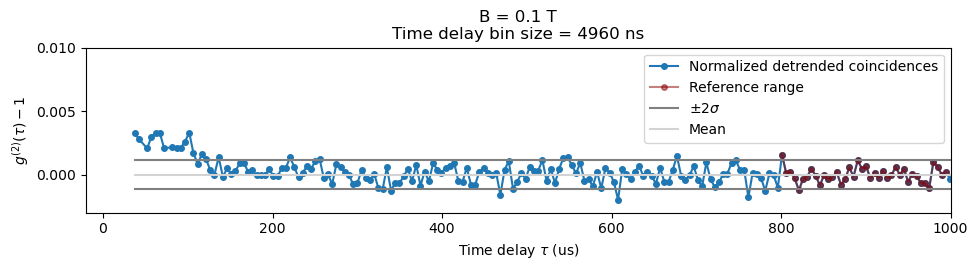

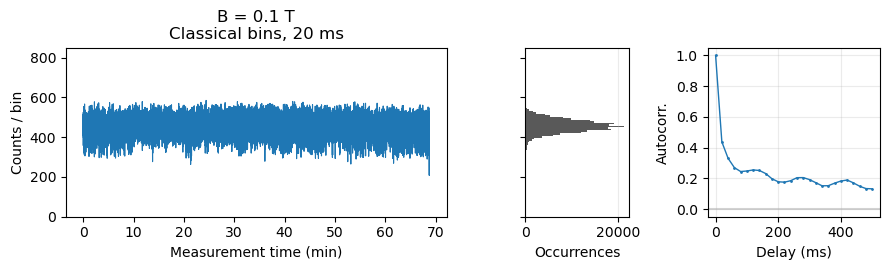

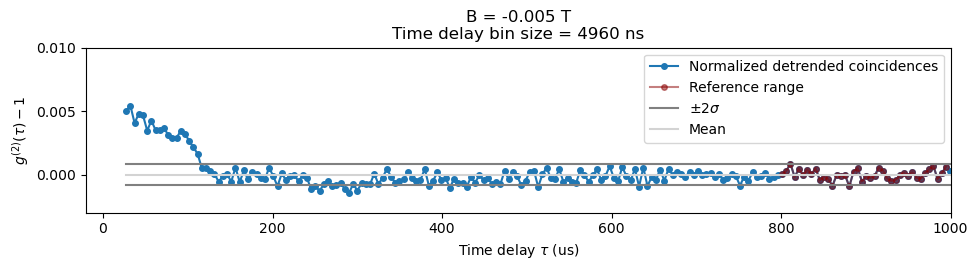

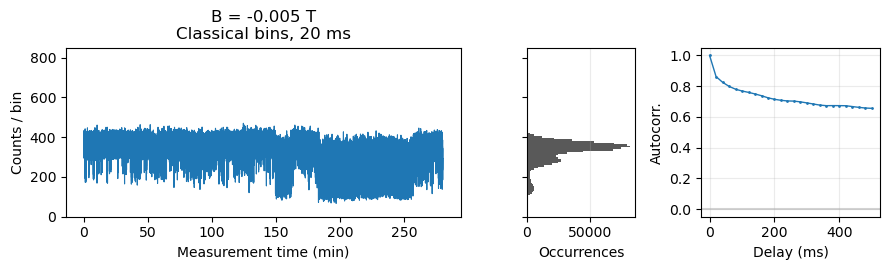

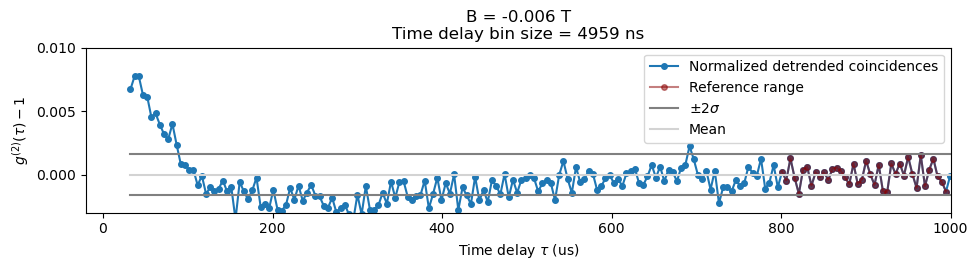

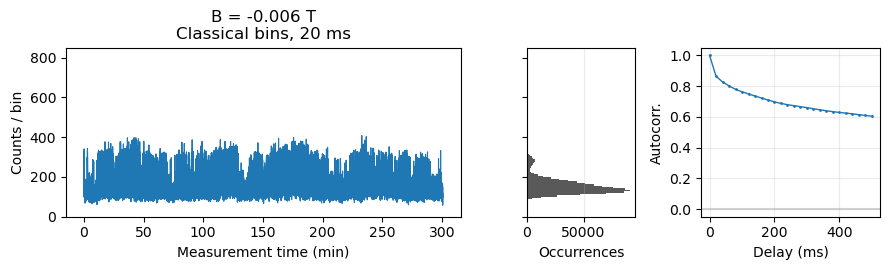

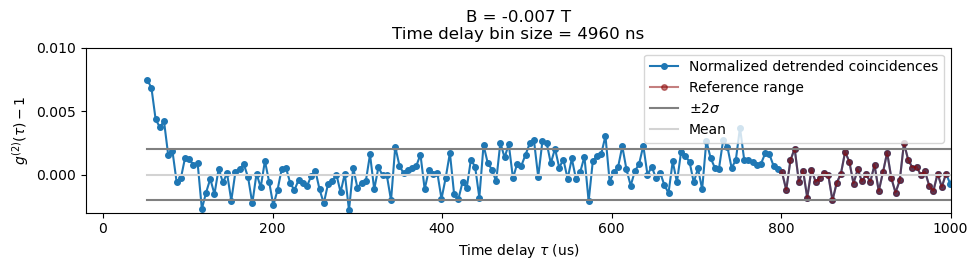

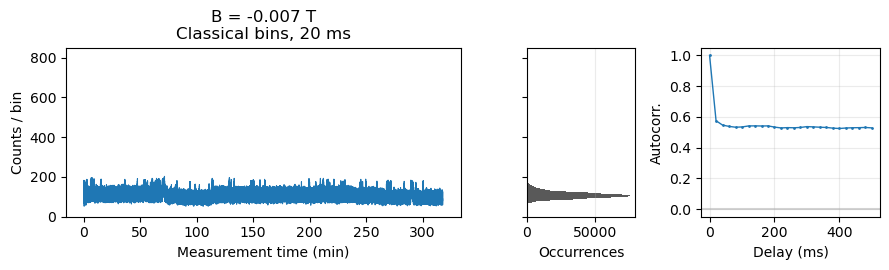

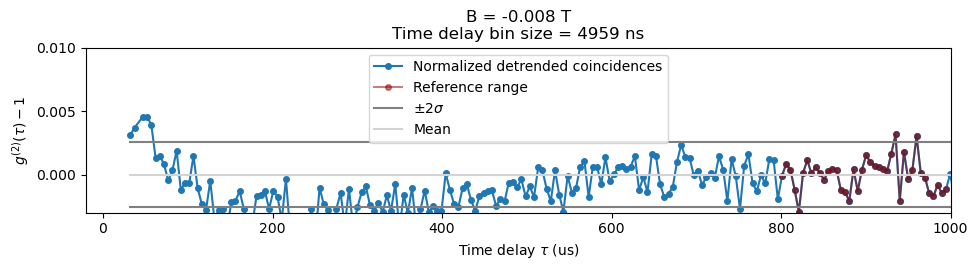

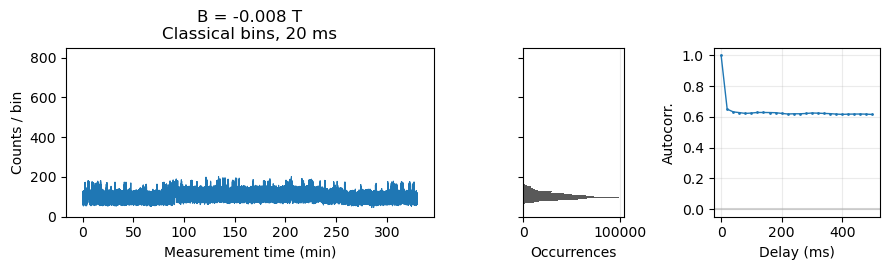

In [22]:
fitres_all = []


# Dataset selection
DATA_ROOT = Path(r"C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE")
DATASETS = [
    {
        "relative_folder": Path(r"20251027\chunks_B_"+f"{B:.3f}V"),
        "filename": "test_chunk0.b",
        "label": f"B = {B} T",
    } for B in [0.1,-0.005,-0.006,-0.007,-0.008]
]

CORRELATION = {
    "delay_min_us": 0.08,
    "delay_max_us": 1_000,
    "bin_width_ps": 40e3,
    "correlation_mode": "X01",
    "worker_count": max(1, min(7, (os.cpu_count() or 8) - 1)),
    "decode_block_records": 10_000_000,
    "show_progress": True,
    "show_max_us":1000,
    "ref_range_us":np.array([800,1000])
}
# Classical binning parameters
CLASSICAL = {
    "bin_width_ms": 20,
    "chunk_minutes": 90,
    "include_channels": None,      # None = all photon channels; or e.g. [0, 1]
    "force_recompute": False,
    "show_progress": True,
}



def dataset_path(dataset):
    return DATA_ROOT / dataset["relative_folder"] / dataset["filename"]

def correlate_dataset(dataset, params=CORRELATION):
    filepath = dataset_path(dataset)
    tau, hist, n_records = analysis_cmd.correlate_b_file_streaming(
        str(filepath),
        tau_min_us=params["delay_min_us"],
        tau_max_us=params["delay_max_us"],
        tau_bin_ps=params["bin_width_ps"],
        n_workers=params["worker_count"],
        mode=params["correlation_mode"],
        block_records=params["decode_block_records"],
        show_progress=params["show_progress"],
    )
    print(f"Finished correlating {n_records / 1e6:.3f} million records in file: {filepath}")
    print(f"Total {np.sum(hist) / 1e9:.6g} billion coincidences in histogram")
    return tau, hist, n_records



results = []
LOAD_EXISTING_CORRELATION = True   # False = recompute 

for dataset in DATASETS:
    filepath = dataset_path(dataset)
    base = str(filepath.parent)
    histogram_name = filepath.name[:-2]  

    if LOAD_EXISTING_CORRELATION:
        hist, tau, params = analysis_cmd.read_existing(
            base,
            name=histogram_name,
            mode=CORRELATION["correlation_mode"],
        )
        n_records = None
        print(f"Loaded existing {CORRELATION['correlation_mode']} histogram: {filepath}")
    else:
        tau, hist, n_records = correlate_dataset(dataset, params=CORRELATION)

    results.append({"dataset": dataset, "tau": tau, "hist": hist, "n_records": n_records})

    latest = results[-1]
    rebin_plot(
        latest["tau"],
        latest["hist"],
        n_new_bins=2e4,
        ref_range_s=CORRELATION["ref_range_us"]*1e-6,
        x_limit_us=CORRELATION["show_max_us"],
        title=latest["dataset"].get("label", latest["dataset"]["filename"]),
        y_limit=[-0.003,0.01],
        savepath  = base
    )

    filepath = dataset_path(dataset)

    classical_data = load_or_create_classical_bins(
        filepath,
        bin_width_ms=CLASSICAL["bin_width_ms"],
        chunk_minutes=CLASSICAL["chunk_minutes"],
        include_channels=CLASSICAL["include_channels"],
        force_recompute=CLASSICAL["force_recompute"],
        show_progress=CLASSICAL["show_progress"],
        
    )

    classical_plot = plot_classical_counts(
        classical_data,
        title=f"{dataset.get('label', dataset['filename'])}\n"
            f"Classical bins, {CLASSICAL['bin_width_ms']} ms",
        histogram_bins = 50,
        y_lims=[0,850],
        ac_xlim_s = 0.5 ,
        savepath = base
    )


In [9]:
analysis_setup()


------------------ LOG ------------------
HydraHarp analysis server reached.
[ANALYSIS - UTC 2026-05-08 16:58:05] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_0.100V
[ANALYSIS - UTC 2026-05-08 16:58:05] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.005V


<Pyro4.core.Proxy at 0x226809744f0; connected IPv4; for PYRO:Analysis_g13@g13-sspd.dhcp-int.phys.ethz.ch:9099>

[ANALYSIS - UTC 2026-05-08 16:58:06] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.006V
[ANALYSIS - UTC 2026-05-08 16:58:07] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.007V
[ANALYSIS - UTC 2026-05-08 16:58:08] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.008V
[ANALYSIS - UTC 2026-05-08 16:58:38] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_0.100V
[ANALYSIS - UTC 2026-05-08 16:58:38] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.005V
[ANALYSIS - UTC 2026-05-08 16:58:39] Reading file with name test_chunk0 in mode X01 from folder 

HydraHarp analysis server reached.
[ANALYSIS - UTC 2026-05-08 16:59:25] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_0.100V
[ANALYSIS - UTC 2026-05-08 16:59:25] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.005V
[ANALYSIS - UTC 2026-05-08 16:59:26] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.006V
[ANALYSIS - UTC 2026-05-08 16:59:27] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.007V
[ANALYSIS - UTC 2026-05-08 16:59:27] Reading file with name test_chunk0 in mode X01 from folder C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.008V
[ANALYSIS - UTC 2026-05-08 17:00:19] Reading file with name t

In [ ]:
# Classical binning parameters
CLASSICAL = {
    "bin_width_ms": 20,
    "chunk_minutes": 72,
    "include_channels": None,      # None = all photon channels; or e.g. [0, 1]
    "force_recompute": False,
    "show_progress": True,
}

dataset = DATASETS[0]
filepath = dataset_path(dataset)

classical_data = load_or_create_classical_bins(
    filepath,
    bin_width_ms=CLASSICAL["bin_width_ms"],
    chunk_minutes=CLASSICAL["chunk_minutes"],
    include_channels=CLASSICAL["include_channels"],
    force_recompute=CLASSICAL["force_recompute"],
    show_progress=CLASSICAL["show_progress"],
)

classical_plot = plot_classical_counts(
    classical_data,
    title=f"{dataset.get('label', dataset['filename'])}\n"
          f"Classical bins, {CLASSICAL['bin_width_ms']} ms",
)
